In [1]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2 qiskit-ibm-runtime==0.50.0


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Google Colab: download the project code (evqaoa/, experiments/, results/) if it is not here yet.
import os, sys
if 'google.colab' in sys.modules and not (os.path.isdir('evqaoa') or os.path.isdir('../evqaoa')):
    !git clone -q https://github.com/SakxamShrestha/quant5-fisk-IQ-hackathon
    %cd quant5-fisk-IQ-hackathon/notebooks

In [2]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT))

# 07 · Is the real-chip result robust?

**Motivation.** Notebook 06 ran our charging-plan circuits once, on one chip (`ibm_fez`). One run cannot tell us whether the numbers belong to the method or to that chip on that day. Here we ask two follow-up questions:

- **A · Does the result hold on a different chip?** We send the same three circuits (same angles, same compiler seed, same error suppression) to a second 156-qubit IBM processor, `ibm_kingston`, and score it exactly like notebook 06.
- **B · Does zero-noise extrapolation (ZNE) recover the noise-free answer?** On `ibm_fez` we run the two XY + Dicke circuits through the Qiskit Runtime Estimator. It repeats each circuit with the noise deliberately amplified (gate folding: noise factors 1, 1.5 and 2), then fits a curve and extrapolates back to noise factor 0.

**Workflow.**
1. Load the saved jobs (or re-submit them when `RUN_ON_IBM = True`).
2. Record what ran: backend, job id, QPU seconds and settings.
3. Part A: score ibm_kingston next to ibm_fez, FakeFez and the ideal simulator; compare the two chips' output distributions with the Hellinger fidelity.
4. Part B: plot the extrapolation curves and compare raw, ZNE, FakeFez and ideal.

**Zero QPU time by default.** With `RUN_ON_IBM = False` the notebook replays the data saved in `results/07_hardware_extra/`, so anyone can re-run it without an IBM account. FakeFez and ideal scores are read from notebook 06's saved results, so no simulation is repeated.

### Running it on your own IBM account
The notebook never contains a token. It reads the account you saved once on your own machine (stored in `~/.qiskit/qiskit-ibm.json`). To save yours, run this **once in a terminal**, not in the notebook:

```python
from qiskit_ibm_runtime import QiskitRuntimeService
QiskitRuntimeService.save_account(channel='ibm_quantum_platform', token='<your API key>',
                                  instance='<your instance CRN>', set_as_default=True)
```

Then set `RUN_ON_IBM = True` below. The two jobs used about 35 s of QPU time together and may wait in the queue. They overwrite the saved files in `results/07_hardware_extra/kingston/` and `.../zne/`.

In [3]:
import os, json, time
import numpy as np
import matplotlib.pyplot as plt
from evqaoa import DEPOT
from experiments import hardware, zne
from experiments.noise import hellinger_fidelity, setup
from experiments.hardware_analysis import (DEVICE_VARIANTS, binomial_std, device_dists, device_scores,
                                           options_summary, plot_grouped_bars, run_names)

RUN_ON_IBM = False        # True = submit both jobs to the real chips (uses QPU time); False = replay saved data
SECOND_CHIP = 'ibm_kingston'
ZNE_CHIP = 'ibm_fez'
KINGSTON_QPU_CAP_S = 30  # max_execution_time for the Sampler job, as in the saved run
# data + outputs live here; EVQAOA_HW07_DIR lets you point the notebook at another folder
OUT = pathlib.Path(os.environ.get('EVQAOA_HW07_DIR', ROOT / 'results' / '07_hardware_extra'))
KING_DIR, ZNE_DIR = OUT / 'kingston', OUT / 'zne'
FEZ_DIR = ROOT / 'results' / '06_hardware'
model, _, base = setup()
RANDOM = dict(valid_rate=base.n_valid / 2 ** DEPOT.n_qubits,          # random 12-bit guess is valid
              p_optimal_valid=base.n_optimal / base.n_valid,           # random valid plan is optimal
              approx_ratio=(base.worst - base.mean) / (base.worst - base.best))
print(f'data folder: {OUT.relative_to(ROOT) if OUT.is_relative_to(ROOT) else OUT}')
print({k: round(v, 4) for k, v in RANDOM.items()}, '<- random-guess reference values')

data folder: results/07_hardware_extra
{'valid_rate': 0.0352, 'p_optimal_valid': 0.0278, 'approx_ratio': 0.6628} <- random-guess reference values


## Step 1 · Run on the chips, or load the saved data
Part A is one SamplerV2 job on ibm_kingston (3 circuits + 2 readout-calibration circuits, 4,096 shots each). Part B is one EstimatorV2 job on ibm_fez (2 circuits x 3 noise factors, 8,192 shots per factor).

In [4]:
if RUN_ON_IBM:
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService()                     # account from ~/.qiskit, never a token here
    hardware.SAMPLER_OPTIONS = {**hardware.SAMPLER_OPTIONS, 'max_execution_time': KINGSTON_QPU_CAP_S}
    jobs = [hardware.submit_runs(service.backend(SECOND_CHIP), list(hardware.RUNS), out_dir=KING_DIR),
            zne.submit_zne(service.backend(ZNE_CHIP), zne.RUN_NAMES, out_dir=ZNE_DIR)]
    t0 = time.time()
    for job in jobs:
        print(f'waiting for job {job.job_id()} ...')
        job.result()                                     # blocks until the job is done
    print(f'both jobs finished after {time.time()-t0:.0f}s')
    hardware.collect(out_dir=KING_DIR, service=service)
    zne.collect_zne(out_dir=ZNE_DIR, service=service)
load = lambda path: json.loads(path.read_text())
king_hw, fez_hw = load(KING_DIR / 'hw_counts.json'), load(FEZ_DIR / 'hw_counts.json')
king_jobs, fez06 = load(KING_DIR / 'jobs.json'), load(FEZ_DIR / 'hardware_results.json')
zne_res, zne_job = load(ZNE_DIR / 'zne_results.json'), load(ZNE_DIR / 'zne_job.json')
RUN_NAMES = run_names(king_hw)
print(f'kingston runs: {RUN_NAMES} | ZNE runs: {list(zne_res["runs"])}')

kingston runs: ['xy_dicke_p2', 'xy_dicke_p1', 'x_penalty_p2'] | ZNE runs: ['xy_dicke_p2', 'xy_dicke_p1']


## Step 2 · What ran
Every hardware job of the project, including notebook 06, with the QPU time IBM charged.

In [5]:
def qpu_s(usage):
    return usage.get('qpu_charge_time_seconds', usage.get('quantum_seconds', float('nan')))

first_king, first_fez = king_hw[RUN_NAMES[0]], fez_hw[RUN_NAMES[0]]
zopt = zne_job['options']
zne_settings = (f"ZNE gate folding x{zne_res['noise_factors']}, {'+'.join(zne_res['extrapolators'])} fits, "
                f"TREX readout, {options_summary(zopt)}")
record = [
    dict(nb='06', backend=first_fez['backend'], job=first_fez['job_id'], primitive='Sampler',
         circuits=f'{len(run_names(fez_hw))} + 2 cal', shots=first_fez['shots'],
         qpu=qpu_s(fez_hw['usage']), settings=options_summary(first_fez['options'])),
    dict(nb='07A', backend=first_king['backend'], job=first_king['job_id'], primitive='Sampler',
         circuits=f'{len(RUN_NAMES)} + 2 cal', shots=first_king['shots'],
         qpu=qpu_s(king_hw['usage']), settings=options_summary(first_king['options'])),
    dict(nb='07B', backend=zne_res['backend'], job=zne_res['job_id'], primitive='Estimator',
         circuits=f"{len(zne_res['runs'])} x {len(zne_res['noise_factors'])} factors",
         shots=zne_res['shots_per_factor'], qpu=qpu_s(zne_res['usage']), settings=zne_settings)]
print(f"{'nb':4s} {'backend':13s} {'job id':22s} {'primitive':9s} {'circuits':16s} shots  QPU s  settings")
for r in record:
    print(f"{r['nb']:4s} {r['backend']:13s} {r['job']:22s} {r['primitive']:9s} {r['circuits']:16s} "
          f"{r['shots']:5d}  {r['qpu']:5}  {r['settings']}")
total_07 = sum(r['qpu'] for r in record if r['nb'].startswith('07'))
total = sum(r['qpu'] for r in record)
print(f'\nQPU time: notebook 07 {total_07} s | notebooks 06 + 07 together {total} s')
print(f"kingston job submitted {king_jobs['timestamp_utc']} | ZNE job submitted {zne_job['timestamp_utc']}")
print('two-qubit gates as compiled (fez / kingston):',
      {n: (fez_hw[n]['circuit_stats']['two_qubit_gates'], king_hw[n]['circuit_stats']['two_qubit_gates'])
       for n in RUN_NAMES})

nb   backend       job id                 primitive circuits         shots  QPU s  settings
06   ibm_fez       dbe13vvgdj9s73fl0mt0   Sampler   3 + 2 cal         4096      8  DD XpXm, twirling gate+measure
07A  ibm_kingston  dbe1m0om94ac738r2si0   Sampler   3 + 2 cal         4096      8  DD XpXm, twirling gate+measure
07B  ibm_fez       dbe1o87gdj9s73fl1ke0   Estimator 2 x 3 factors     8192     25  ZNE gate folding x[1, 1.5, 2], exponential+linear fits, TREX readout, DD XpXm, twirling gate+measure

QPU time: notebook 07 33 s | notebooks 06 + 07 together 41 s
kingston job submitted 2026-10-24T02:42:11.754358+00:00 | ZNE job submitted 2026-10-24T02:46:56.994597+00:00
two-qubit gates as compiled (fez / kingston): {'xy_dicke_p2': (357, 357), 'xy_dicke_p1': (209, 209), 'x_penalty_p2': (305, 305)}


## Part A · Same circuits, second chip
Both chips are scored with the same code as notebook 06: raw counts, readout-corrected counts (from each job's own calibration circuits) and post-selected counts (invalid shots discarded). Ideal and FakeFez numbers come from notebook 06's saved results.

In [6]:
METRIC_KEYS = ('valid_rate', 'p_optimal', 'p_optimal_valid', 'approx_ratio')
chips = {'ibm_fez': fez_hw, 'ibm_kingston': king_hw}
scores = {n: {chip: device_scores(hw, n, model, base) for chip, hw in chips.items()} for n in RUN_NAMES}
dists = {n: {chip: device_dists(hw, n) for chip, hw in chips.items()} for n in RUN_NAMES}

# cross-check: the scores recomputed here match the saved kingston_results.json (no hidden step)
saved = load(KING_DIR / 'kingston_results.json')['runs']
for n in RUN_NAMES:
    for chip, key in (('ibm_kingston', 'kingston'), ('ibm_fez', 'fez')):
        for v in DEVICE_VARIANTS:
            for m in METRIC_KEYS:
                assert abs(scores[n][chip][v][m] - saved[n][key][v][m]) < 1e-9, (n, chip, v, m)
print('recomputed scores match kingston_results.json')

print(f"\n{'run':13s} {'source':30s} valid  P(opt) P(opt|valid) approx  valid shots")
for n in RUN_NAMES:
    rows = [('ideal simulator', fez06['runs'][n]['scores']['ideal'], None),
            ('FakeFez (noisy sim)', fez06['runs'][n]['scores']['fakefez'], None)]
    rows += [(f'{chip} {v}', scores[n][chip][v], chips[chip][n]['shots'])
             for chip in chips for v in DEVICE_VARIANTS[:2]]
    for label, s, shots in rows:
        nv = f"{round(s['valid_rate'] * shots):6d}" if shots and 'raw' in label else ''
        print(f"{n:13s} {label:30s} {s['valid_rate']:.3f}  {s['p_optimal']:.4f} {s['p_optimal_valid']:.4f}"
              f"       {s['approx_ratio']:.3f}  {nv}")

recomputed scores match kingston_results.json

run           source                         valid  P(opt) P(opt|valid) approx  valid shots
xy_dicke_p2   ideal simulator                1.000  0.1038 0.1038       0.807  
xy_dicke_p2   FakeFez (noisy sim)            0.341  0.0278 0.0817       0.779  
xy_dicke_p2   ibm_fez raw                    0.169  0.0117 0.0695       0.757     691
xy_dicke_p2   ibm_fez readout_corrected      0.179  0.0129 0.0719       0.760  
xy_dicke_p2   ibm_kingston raw               0.292  0.0244 0.0835       0.780    1197
xy_dicke_p2   ibm_kingston readout_corrected 0.324  0.0276 0.0853       0.782  
xy_dicke_p1   ideal simulator                1.000  0.0326 0.0326       0.719  
xy_dicke_p1   FakeFez (noisy sim)            0.510  0.0183 0.0359       0.710  
xy_dicke_p1   ibm_fez raw                    0.261  0.0081 0.0308       0.701    1070
xy_dicke_p1   ibm_fez readout_corrected      0.285  0.0088 0.0308       0.701  
xy_dicke_p1   ibm_kingston raw             

### Plot · Four sources side by side
Valid share, chance of the optimal plan once invalid shots are discarded, and approximation ratio. Error bars on the sampled sources are the binomial shot-noise standard error (P(opt|valid) uses the number of valid shots, so it is the noisiest). Dashed lines: a random guess.

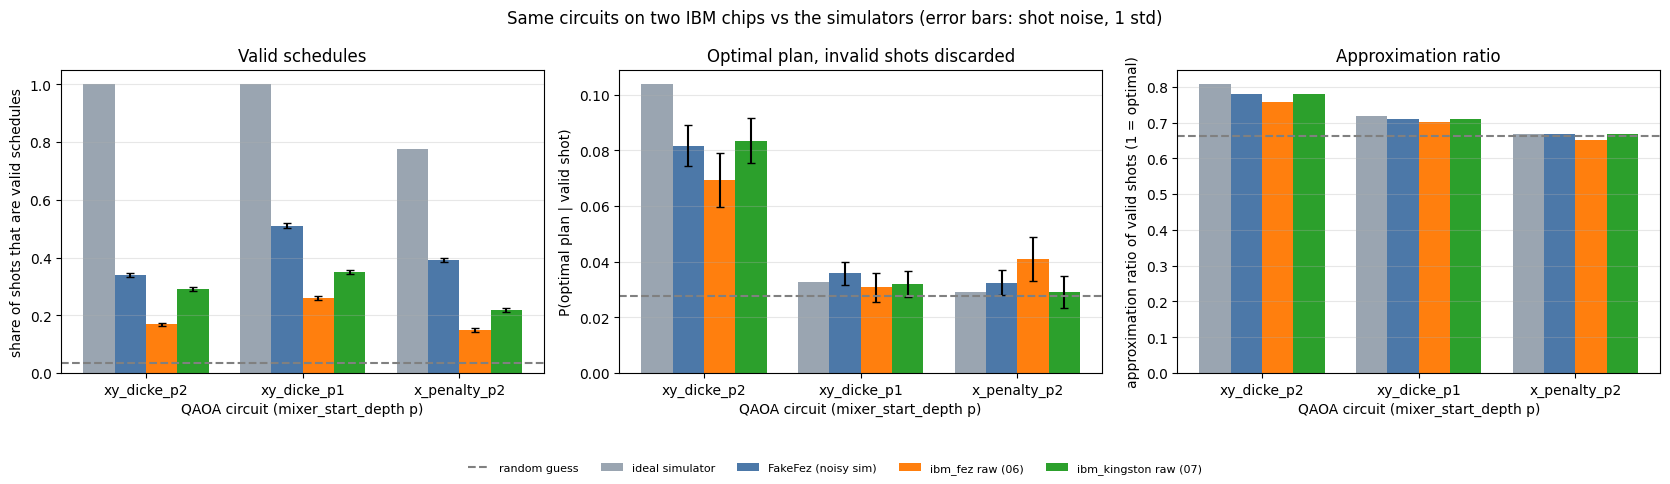

In [7]:
SRC = {'ideal': 'ideal simulator', 'fakefez': 'FakeFez (noisy sim)',
       'ibm_fez': 'ibm_fez raw (06)', 'ibm_kingston': 'ibm_kingston raw (07)'}
CHIP_COLORS = dict(zip(SRC.values(), ('#9aa5b1', '#4c78a8', 'tab:orange', '#2ca02c')))

def with_errors(s, shots):
    n_valid = s['valid_rate'] * shots
    return dict(valid_rate=binomial_std(s['valid_rate'], shots),
                p_optimal_valid=binomial_std(s['p_optimal_valid'], n_valid))

table, errors = {}, {}
for n in RUN_NAMES:
    srcs = {'ideal': fez06['runs'][n]['scores']['ideal'], 'fakefez': fez06['runs'][n]['scores']['fakefez'],
            **{chip: scores[n][chip]['raw'] for chip in chips}}
    table[n] = {SRC[k]: s for k, s in srcs.items()}
    shots = {'fakefez': fez_hw[n]['shots'], **{chip: chips[chip][n]['shots'] for chip in chips}}
    errors[n] = {SRC[k]: with_errors(srcs[k], shots[k]) for k in shots}
CHIP_METRICS = (('valid_rate', 'share of shots that are valid schedules', 'Valid schedules'),
                ('p_optimal_valid', 'P(optimal plan | valid shot)', 'Optimal plan, invalid shots discarded'),
                ('approx_ratio', 'approximation ratio of valid shots (1 = optimal)', 'Approximation ratio'))
plot_grouped_bars(table, OUT / 'chips_fez_vs_kingston.png', CHIP_METRICS, CHIP_COLORS,
                  'Same circuits on two IBM chips vs the simulators (error bars: shot noise, 1 std)',
                  errors=errors, reference=RANDOM)
plt.show()

### Hellinger fidelity · how alike are the two chips' outputs?
1 means identical distributions over the 4,096 bitstrings. Raw outputs are dominated by noise spread over invalid bitstrings; after discarding invalid shots we compare only the 144 valid plans.

In [8]:
HELL_VARIANTS = dict(raw='raw', readout_corrected='readout-corrected', invalid_discarded='invalid discarded')
hellinger = {}
print(f"{'run':13s} " + ' '.join(f'{v:>18s}' for v in HELL_VARIANTS.values()) + '   fez vs ideal  kingston vs ideal')
for n in RUN_NAMES:
    d = dists[n]
    hellinger[n] = {v: hellinger_fidelity(d['ibm_kingston'][v], d['ibm_fez'][v]) for v in HELL_VARIANTS}
    hellinger[n].update(fez_vs_ideal=saved[n]['hellinger']['fez_vs_ideal'],
                        kingston_vs_ideal=saved[n]['hellinger']['kingston_vs_ideal'])
    print(f'{n:13s} ' + ' '.join(f'{hellinger[n][v]:18.3f}' for v in HELL_VARIANTS) +
          f"   {hellinger[n]['fez_vs_ideal']:12.3f}  {hellinger[n]['kingston_vs_ideal']:17.3f}")
    assert abs(hellinger[n]['raw'] - saved[n]['hellinger']['kingston_vs_fez_raw']) < 1e-9
print('(columns 1-3: kingston vs fez; chip-vs-ideal values use raw counts, computed in kingston_results.json)')

run                          raw  readout-corrected  invalid discarded   fez vs ideal  kingston vs ideal
xy_dicke_p2                0.457              0.421              0.851          0.137              0.266
xy_dicke_p1                0.524              0.494              0.938          0.251              0.341
x_penalty_p2               0.426              0.413              0.842          0.318              0.435
(columns 1-3: kingston vs fez; chip-vs-ideal values use raw counts, computed in kingston_results.json)


## Part B · Zero-noise extrapolation on ibm_fez
The Estimator measures each score as the expectation value of a projector (P(valid), P(optimal)) or of the cost Hamiltonian, at noise factors 1, 1.5 and 2. The server then fits each Pauli term and reports a value at noise factor 0 with an error bar. Its global exponential fit returned no value (NaN) for this data, so the reported ZNE number is the server's per-term best fit; we also show the linear fit, which is stored separately.

In [9]:
print(f"{'run':12s} {'score':10s} {'ideal':>7s} {'06 raw':>7s} " +
      ' '.join(f'{"f=" + str(f):>7s}' for f in zne_res['noise_factors']) +
      f" {'linear@0':>16s} {'ZNE (best fit)':>17s}")
for n, run in zne_res['runs'].items():
    for key in ('p_valid', 'p_optimal'):
        row = run['observables'][key]
        lin = row['extrapolated']['linear']
        pts = ' '.join(f"{p['value']:7.4f}" for p in row['per_factor'])
        print(f"{n:12s} {key:10s} {row['ideal']:7.4f} {run['study06_sampler_raw'][key]:7.4f} {pts} "
              f"{lin['values'][0]:8.4f}±{lin['stds'][0]:.4f} {row['zne']:9.4f}±{row['zne_std']:.4f}")
    r = run['approx_ratio']
    pts = ' '.join(f"{p['value']:7.3f}" for p in r['per_factor'])
    print(f"{n:12s} {'approx':10s} {r['ideal']:7.3f} {run['study06_sampler_raw']['approx_ratio']:7.3f} {pts} "
          f"{'':16s} {r['zne']['value']:9.3f}±{r['zne']['std']:.3f}")

run          score        ideal  06 raw     f=1   f=1.5     f=2         linear@0    ZNE (best fit)
xy_dicke_p2  p_valid     1.0000  0.1687  0.1599  0.0768  0.0592   0.2493±0.0183    0.3947±0.0393
xy_dicke_p2  p_optimal   0.1038  0.0117  0.0107  0.0025  0.0017   0.0183±0.0019    0.0353±0.0050
xy_dicke_p2  approx       0.807   0.757   0.750   0.704   0.693                      0.782±0.264
xy_dicke_p1  p_valid     1.0000  0.2612  0.2759  0.1236  0.0939   0.4375±0.0256    0.6685±0.0448
xy_dicke_p1  p_optimal   0.0326  0.0081  0.0090  0.0045  0.0014   0.0165±0.0019    0.0213±0.0052
xy_dicke_p1  approx       0.719   0.701   0.695   0.694   0.686                      0.695±0.183


### Plot · Extrapolation curves
Orange points: the chip at each noise factor (1 std error bars). Red square: the ZNE estimate at noise factor 0. Blue dash-dot line: the linear fit. Grey dashed line: the noise-free value.

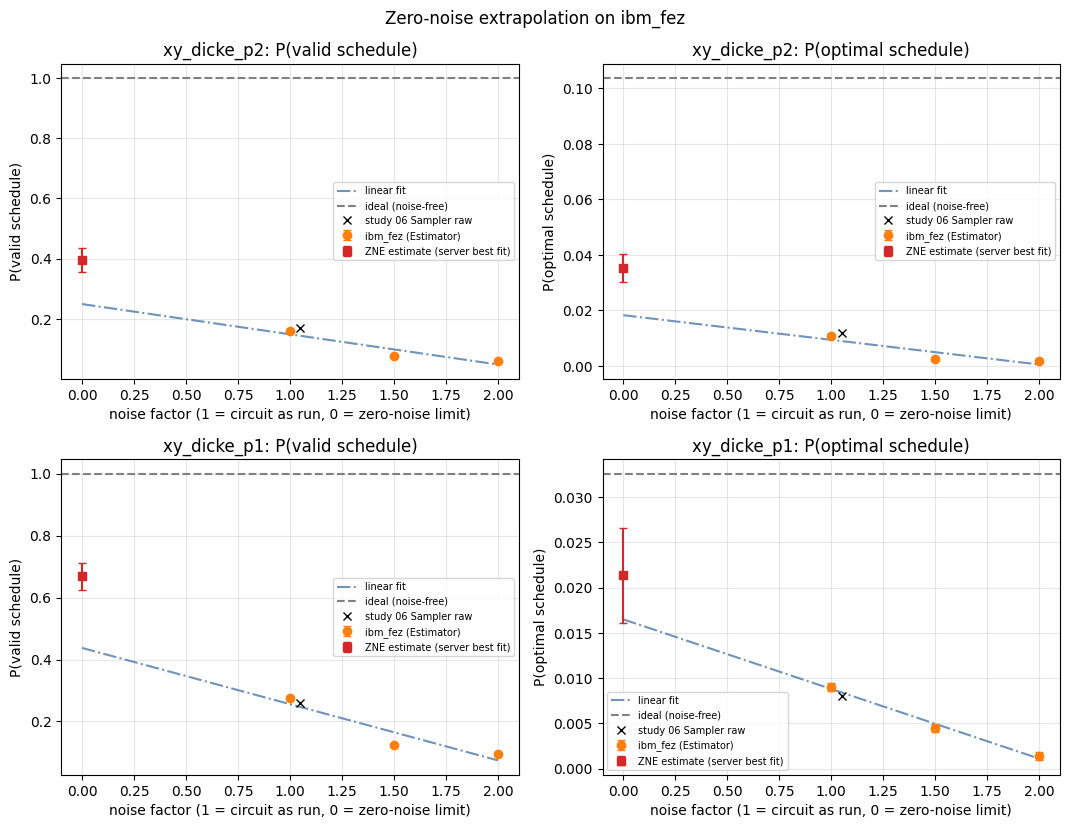

In [10]:
zne.plot_extrapolation(zne_res, OUT / 'zne_extrapolation_curves.png',
                       metrics=zne.PLOTTED[:2])
plt.show()

### Plot · How much does ZNE close the gap?
Same circuits, five sources. Error bars on the two Estimator sources are the server's 1 std errors.

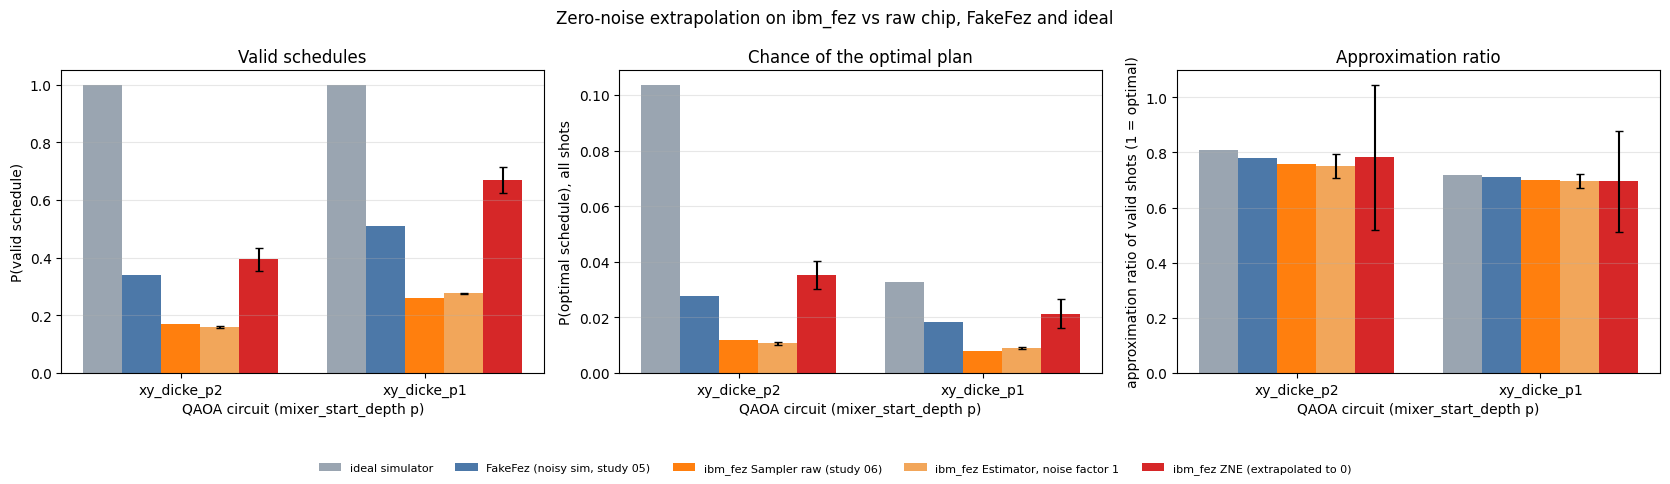

xy_dicke_p2  p_valid    ZNE closes 27.9% of the gap to ideal (factor-1 value 0.1599 -> ZNE 0.3947, ideal 1.0000)
xy_dicke_p2  p_optimal  ZNE closes 26.4% of the gap to ideal (factor-1 value 0.0107 -> ZNE 0.0353, ideal 0.1038)
xy_dicke_p1  p_valid    ZNE closes 54.2% of the gap to ideal (factor-1 value 0.2759 -> ZNE 0.6685, ideal 1.0000)
xy_dicke_p1  p_optimal  ZNE closes 52.4% of the gap to ideal (factor-1 value 0.0090 -> ZNE 0.0213, ideal 0.0326)


In [11]:
zne_table, zne_errors = zne.zne_bar_table(zne_res)
ZNE_METRICS = (('p_valid', 'P(valid schedule)', 'Valid schedules'),
               ('p_optimal', 'P(optimal schedule), all shots', 'Chance of the optimal plan'),
               ('approx_ratio', 'approximation ratio of valid shots (1 = optimal)', 'Approximation ratio'))
plot_grouped_bars(zne_table, OUT / 'zne_vs_raw_summary.png', ZNE_METRICS, zne.ZNE_COLORS,
                  'Zero-noise extrapolation on ibm_fez vs raw chip, FakeFez and ideal',
                  errors=zne_errors)
plt.show()
for n, row in zne_table.items():
    ideal_src, zne_src, unmit_src = zne.ZNE_SOURCES[0], zne.ZNE_SOURCES[-1], zne.ZNE_SOURCES[-2]
    for key in ('p_valid', 'p_optimal'):
        gap_raw = row[ideal_src][key] - row[unmit_src][key]
        gap_zne = row[ideal_src][key] - row[zne_src][key]
        print(f'{n:12s} {key:10s} ZNE closes {1 - gap_zne / gap_raw:5.1%} of the gap to ideal '
              f'(factor-1 value {row[unmit_src][key]:.4f} -> ZNE {row[zne_src][key]:.4f}, ideal {row[ideal_src][key]:.4f})')

## Step 3 · Save every number

In [12]:
summary = dict(record=record, qpu_seconds=dict(notebook_07=total_07, notebooks_06_07=total),
               random_reference=RANDOM,
               part_a=dict(scores=scores, hellinger_kingston_vs_fez=hellinger,
                           ideal_fakefez={n: {k: fez06['runs'][n]['scores'][k] for k in ('ideal', 'fakefez')}
                                          for n in RUN_NAMES}),
               part_b=dict(table=zne_table, errors=zne_errors))
(OUT / 'robustness_summary.json').write_text(json.dumps(summary, indent=2))
print('saved', sorted(p.name for p in OUT.iterdir()))

saved ['chips_fez_vs_kingston.png', 'kingston', 'robustness_summary.json', 'zne', 'zne_extrapolation_curves.png', 'zne_vs_raw_summary.png']


## Findings & limitations

**Run record.** Two new jobs, no simulator stand-ins. Part A: one SamplerV2 job on **ibm_kingston** (job `dbe1m0om94ac738r2si0`), the same 3 circuits as notebook 06 plus 2 readout-calibration circuits, 4,096 shots each, DD (XpXm) and gate + measurement twirling, **8 s of QPU time**. Part B: one EstimatorV2 job on **ibm_fez** (job `dbe1o87gdj9s73fl1ke0`), the two XY + Dicke circuits at gate-folding noise factors 1, 1.5 and 2, 8,192 shots per factor, TREX readout mitigation, DD and twirling, **25 s of QPU time**. Notebooks 06 and 07 together used **41 s** of QPU time.

**A · Does the result hold on a different chip?**

1. **Yes, the pattern holds, and kingston is less noisy.** Same circuits, same 357 / 209 / 305 two-qubit gates after compiling. Valid share on kingston was 29.2% / 35.1% / 21.8% (XY + Dicke p = 2 / p = 1 / X + penalty p = 2), against 16.9% / 26.1% / 14.9% on fez. That is 1.3–1.7× more valid shots. These gaps are 8–13 times the combined shot noise, so they are real device differences.
2. **The FakeFez prediction is still optimistic.** FakeFez said 34.1% / 51.0% / 39.1%. Kingston sits between fez and FakeFez on every circuit. So "a noisy simulator is an upper bound" holds on both chips.
3. **The post-selected answer agrees across chips.** With invalid shots discarded, XY + Dicke p = 2 finds the optimal plan 8.35% of the time on kingston and 6.95% on fez (random valid plan: 2.8%). The difference is about one standard error of shot noise, so the two chips agree. XY + Dicke p = 2 is the only circuit clearly above random on both. The p = 1 and penalty circuits sit at 2.9–4.1%, close to random.
4. **The approximation ratio barely moves.** Valid shots score 0.780 (kingston) and 0.757 (fez) against 0.807 ideal for p = 2.
5. **The two chips' raw outputs look different, their valid outputs look alike.** Hellinger fidelity kingston vs fez is only 0.43–0.52 on raw counts (0.41–0.49 readout-corrected), because each chip spreads its noise over different invalid bitstrings. Over valid plans only it is 0.84–0.94.

**B · Does ZNE recover the noise-free answer?**

6. **ZNE moves the numbers the right way but only part of the way.** For XY + Dicke p = 2, P(valid) goes from 0.160 at noise factor 1 to **0.395 ± 0.039** after ZNE (ideal 1.0). P(optimal) goes from 0.0107 to **0.035 ± 0.005** (ideal 0.104). That closes about 27% of the gap to ideal. For the shallower p = 1 circuit, P(valid) goes from 0.276 to **0.669 ± 0.045** and P(optimal) from 0.0090 to 0.021 ± 0.005 (ideal 0.033), closing about 53% of the gap.
7. **The ZNE value depends on the fit.** The server's exponential fit returned no value (NaN). The reported number is its per-term best fit. A plain linear fit through the same three points gives much less: 0.249 for p = 2 P(valid) and 0.438 for p = 1.
8. **ZNE does not help the approximation ratio.** It is a ratio of two extrapolated values, so its error bar grows to ±0.18–0.26. The ZNE value (0.78 for p = 2) is not distinguishable from the raw value (0.75) or from ideal (0.81).

**Limitations**

- Each chip was run once, on a single day (the two notebook-07 jobs were submitted four minutes apart; the fez Sampler job is notebook 06's, from earlier the same day). Calibration drifts, so day-to-day variation is not measured. Two chips are still a small sample.
- Shot noise is significant for the post-selected numbers. P(optimal | valid) rests on about 600–1,400 valid shots per run, roughly ±0.5–1 percentage point. The fez vs kingston difference in P(optimal | valid) is within that noise.
- ZNE is biased at this circuit depth. Even at noise factor 1 the p = 2 circuit keeps only 16% of its valid share. At factor 2 it keeps 6%, so little signal is left to fit. Three noise factors cannot pin down the shape of the decay, which is why the exponential fit failed and the linear and best-fit answers disagree.
- ZNE error bars are large (±0.04 on P(valid), ±0.2–0.26 on the approximation ratio) and come from the server's fit, not from repeated runs.
- ZNE was only tried on ibm_fez, and only on the two XY + Dicke circuits.
